In [2]:
import numpy as np
import matplotlib.pyplot as plt
from ase.calculators.calculator import Calculator, all_changes
from ase.build import fcc100, add_adsorbate
from ase.dimer import DimerControl, MinModeAtoms, MinModeTranslate
from ase.optimize import FIRE,BFGS
from ase.constraints import FixedPlane
from ase.io import Trajectory
import copy

In [ ]:
import jax.numpy as jnp
from jax import jit
from jax import grad ,jacfwd,jacrev


class General_Bias_Calculator(Calculator):
    """ This a class of general bias calculator it can calculate energy, force. For doing so a bias function and a function that defines the variables for the bais function
        are necessary. To obtain the force it is necessary to calculate the derivatives of the given bias function. This done by using the auto gradient function 'grad()'
        from JAX. To obtain the derivative(s) of the collective variables the Jacobian matrix of the these is generated with 'jacfwd()'.
        
        
        Parameters
        ----------
        cv_function:    python function (will be optional later)
                        This function should only dependend on the atoms postions of the atom object later used  
                        If all cartesian coordiantes should be used just flatten the atoms postions array as the cv_function (should be tested for systems of different size)
                      
        bias_function:  python function, necessary
                        This the function the Calculator is based on! It should only have a single input, the set of collective variable in form of an 1D array!
                        
        use_jit:        boolean, optional
                        Allows just in time compilation of all used functions and thier derivatives
    """
    implemented_properties=['energy','forces']#,'hessian']
    def __init__(self, cv_function, bias_function, use_jit = True, **kwargs):
        """ Sets up the Calculator from ase for example self.results or allows get_forces (and similar things) to work"""
        Calculator.__init__(self, **kwargs)

        self.use_jit = use_jit
        
        if self.use_jit:
            self.bias_function = jit(bias_function)
            self.deriv_bias_function = jit(grad(self.bias_function))
            
            self.cv_function = jit(cv_function)
            self.deriv_cv = jit(jacfwd(cv_function))
            
            #self.hessian_bias_funtion = jit(self.calc_hessian(self.bias_function))

        else:
            self.bias_function = bias_function
            self.deriv_bias_function = grad(self.bias_function)
            
            self.cv_function = cv_function
            self.deriv_cv = jacfwd(cv_function)
            
            #self.hessian_bias_funtion = self.calc_hessian(self.bias_function)

    
    def calculate(self, atoms=None, properties=['energy','forces'], system_changes=all_changes):
        """ Calculates all the implemented properties. This method needs to call the .calculate form the Calculator class"""

        Calculator.calculate(self, atoms, properties, system_changes) # for setting up all necessary stuff DO NOT define ANY stuff by hand this method defines! otherwise it won't recoginze changes
        #print('prop', properties)
       
        self.energy = 0
        
        atoms_pos = atoms.get_positions()

        self.cvs = self.cv_function(atoms_pos)
        #print('CVs ', self.cvs)
        self.energy += self.bias_function(self.cvs)
        #print('Energy' ,self.energy)

        if 'forces' in properties: 
            self.forces = self.calc_forces(atoms_pos,self.cvs)
            #print(self.forces)
            
            self.results['forces'] = np.asarray(self.forces)
        
        if 'stress' in properties:
            self.stress = +0
            pass

        if 'hessian' in properties:
            self.hessian = self.hessian_bias_funtion(atoms_pos).reshape(len(atoms)*3,len(atoms)*3)

        self.results['energy'] = self.energy
        #print(self.results)
        
    
    def calc_forces(self,atoms_pos,cvs):
        """ This method calculates the force based on the given function for the initializing the Calculator. Force obtainting the force ther derivative of the energy with respect to 
            the collective varriables and the derivative of the collective variables with respect to the cartesian coordinates of the atom postions are necessary.
            
            transfering to np arrays is super important other wise the constraints are not working and the code will crash
        """
        ### Sets up an force array of zeros with the right dimensions! 
        force_array = self.set_force_array(atoms_pos)
        #print('Empty Force ', force_array)
        
        ### Calcs derivative of the Energy with respect to the collective variables
        self.deriv_E = self.calc_deriv_E_to_cvs(cvs)
        #print('deriv_E', self.deriv_E) 
        
        ### Calcs derivative of the collective varriable with respect to the cartesian coordiantes of the atom postions
        self.deriv_cvs = self.calc_deriv_cvs(atoms_pos)
        #print('deriv_cvs', self.deriv_cvs) 
        #print(np.dot(self.deriv_E,self.deriv_cvs))
        force_array -=np.dot(self.deriv_E,self.deriv_cvs) #dimensions (number of atom(s), coordinates of the atom)
        return force_array
    
    
    def set_force_array(self,atoms_pos):
        return np.zeros(atoms_pos.shape)
    
    
    def calc_deriv_E_to_cvs(self,cvs):
        ''' Calcs derivative of the Energy with respect to the collective variable'''
        return np.asarray(self.deriv_bias_function(cvs)) # dimensions (collective variables)
    
    
    def calc_deriv_cvs(self,atoms_pos):
        '''Calcs derivative of the collective varriable with respect to the cartesian coordiantes of the atom postions'''
        jacobian = np.asarray(self.deriv_cv(atoms_pos))
                              
        if jacobian.ndim == 3:
            return np.moveaxis(jacobian,[0],[1]) #Dimensons (number of atom(s),collective variables, coodrinates of the atom)
        elif jacobian.ndim == 2:
            return jacobian
        else:
            return 'There is an Error in the dimenstions of the CV derivative'
    
    def calc_hessian(self,f):
        ''' Gives the hessian of the energy with respect to the CVs'''
        return jacfwd(jacrev(f))


    def get_hessian(self):
        ''' There is no get_hessian definde in the ASE calculator class'''
        return self.results['hessian']
    
    

def numerical_deriv(atom_pos,f,cv):
    pass

# Let's try the General_Bias_Calculator

We start with a simple 2D function (a Double-Well) where the x and the y coordinates of and single Atom are the two collective variables, we ignore z for now! <br>
For checking if it works we will calculate the numerical derivatives with respect of x and y. <br>
We will just define a single atom (there are easier ways and the fcc100 for sure but this allow easy adjustment of the number of atoms!) <br>
We will also directly freeze the atom into the x,y plane (can be commented out should still work) because constraints can be trouble makers for calculators. <br>

In [4]:
def _cvs(atom_pos):
    '''Collective variable from the x and y cooridinate'''
    x = atom_pos[0][0]
    y = atom_pos[0][1]
    return jnp.array([x,y])

def f_dw_cvs(cvs):
    '''Double-Well'''
    x =  cvs[0]
    y =  cvs[1]
    return (x**2 - 1)**2 + y**2

# Function with "cv" directly in it and numerical derivatives for x and y 
def f_dw(x,y):
    return (x**2 - 1)**2 + y**2
def f_dw_d_df_dx(x, y, h):
    return float((f_dw(x+h, y) - f_dw(x-h, y)) / (2*h))

def f_dw_d_df_dy(x, y, h):
    return float((f_dw(x, y+h) - f_dw(x, y-h)) / (2*h))

In [5]:
# Set up the system

atoms = fcc100('Pd', size=(1, 1, 1), vacuum=10.0)
# Slight displace ment for not only 0 as result
pos = atoms.get_positions()
pos[0][0]+=1e-1
pos[0][1]+=1e-1
pos[0][2]+=1e-1
atoms.set_positions(pos)

#Setting constraints
c = FixedPlane(indices=[atom.index for atom in atoms], direction=[0, 0, 1])

atoms.set_constraint(c)

initial = copy.deepcopy(atoms) #Artifact from copy past

# Set up the General_Bias_Calculator
jax_calc = General_Bias_Calculator(_cvs,f_dw_cvs)
initial.calc =jax_calc 

print('Energy', initial.get_potential_energy())
print('Force', initial.get_forces())
pos = initial.get_positions()
print('Num_Energy',f_dw(pos[0][0],pos[0][1]))
print('Num_Force',[-f_dw_d_df_dx(pos[0][0],pos[0][1],h=1e-4),-f_dw_d_df_dy(pos[0][0],pos[0][1],h=1e-4),0])

Energy 0.9901
Force [[ 0.396 -0.2    0.   ]]
Num_Energy 0.9901
Num_Force [0.39599999599959634, -0.1999999999996449, 0]


# Let's try a different function!

In [6]:
def f_cvs(cvs):
    x = cvs[0]
    y = cvs[1]
    r = jnp.sqrt(x**2 + y**2)
    large_min = jnp.exp(-0.5*((r)/0.5)**2)
    small_mins = 0
    for i in range(5):
        x0 = 2*jnp.cos(2*jnp.pi*i/5)
        y0 = 2*jnp.sin(2*jnp.pi*i/5)
        small_mins += 1*jnp.exp(-0.5*((x-x0)**2 + (y-y0)**2)/0.2**2)

        x1 = 2.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/5)
        y1 = 2.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/5)
        small_mins += 0.8*jnp.exp(-0.2*((x-x1)**2 + (y-y1)**2)/0.2**2)

        x2=4.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/(2.5))
        y2= 4.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/(2.5))
        small_mins += 1*jnp.exp(-0.1*((x-x2)**2 + (y-y2)**2)/0.2**2)

    return -10*large_min - 10*small_mins + (x**2 +y**2)

def _cvs(atom_pos):
    x = atom_pos[0][0]
    y = atom_pos[0][1]
    return jnp.array([x,y])


def f(x,y):
    r = jnp.sqrt(x**2 + y**2)
    large_min = jnp.exp(-0.5*((r)/0.5)**2)
    small_mins = 0
    for i in range(5):
        x0 = 2*jnp.cos(2*jnp.pi*i/5)
        y0 = 2*jnp.sin(2*jnp.pi*i/5)
        small_mins += 1*jnp.exp(-0.5*((x-x0)**2 + (y-y0)**2)/0.2**2)

        x1 = 2.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/5)
        y1 = 2.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/5)
        small_mins += 0.8*jnp.exp(-0.2*((x-x1)**2 + (y-y1)**2)/0.2**2)

        x2=4.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/(2.5))
        y2= 4.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/(2.5))
        small_mins += 1*jnp.exp(-0.1*((x-x2)**2 + (y-y2)**2)/0.2**2)

    return -10*large_min - 10*small_mins + (x**2 +y**2)
def fd_df_dx(x, y, h):
    return float((f(x+h, y) - f(x-h, y)) / (2*h))

def fd_df_dy(x, y, h):
    return float((f(x, y+h) - f(x, y-h)) / (2*h))

In [7]:
atoms = fcc100('Pd', size=(1, 1, 1), vacuum=10.0)

pos = atoms.get_positions()
pos[0][0]+=1e-1
pos[0][1]+=1e-1
pos[0][2]+=1e-1
atoms.set_positions(pos)
c = FixedPlane(indices=[atom.index for atom in atoms], direction=[0, 0, 1])

atoms.set_constraint(c)

initial = copy.deepcopy(atoms)

jax_calc = General_Bias_Calculator(_cvs,f_cvs)
initial.calc =jax_calc

print('Energy', initial.get_potential_energy())
print('Force', initial.get_forces())
pos = initial.get_positions()

print('Num_Energy',f(pos[0][0],pos[0][1]))
print('Num_Force',[-fd_df_dx(pos[0][0],pos[0][1],h=1e-4),-fd_df_dy(pos[0][0],pos[0][1],h=1e-4),0])

Energy -9.587894
Force [[-4.04315758 -4.04315758  0.        ]]
Num_Energy -9.587894
Num_Force [-4.0435791015625, -4.0435791015625, 0]


# Let's try more dimensions and a larger system

Instead of just two coodrinates form a single atom, we now want to use two coodrinates from one atom and one additional coordinate from a second atom

In [8]:
def _cvs_dwz(atom_pos):
    x = atom_pos[0][0]
    y = atom_pos[0][1]
    z = atom_pos[1][1]
    return jnp.array([x,y,z])

def f_dwz_cvs(cvs):
    x =  cvs[0]
    y =  cvs[1]
    z =  cvs[2]
    return (x**2 - 1)**2 + y**2 +z



def f_dwz(x,y,z):
    return (x**2 - 1)**2 + y**2 +z 


def f_dwz_d_df_dx(x, y, z, h):
    return float((f_dwz(x+h, y, z) - f_dwz(x-h, y, z)) / (2*h))

def f_dwz_d_df_dy(x, y, z, h):
    return float((f_dwz(x, y+h, z) - f_dwz(x, y-h, z)) / (2*h))

def f_dwz_d_df_dz(x, y, z, h):
    return float((f_dwz(x, y, z+h) - f_dwz(x, y, z-h)) / (2*h))

In [9]:
atoms = fcc100('Pd', size=(2, 1, 1), vacuum=10.0)

pos = atoms.get_positions()
pos[0][0]+=1e-1
pos[0][1]+=1e-1
pos[1][1]+=1e-1
atoms.set_positions(pos)
c = FixedPlane(indices=[atom.index for atom in atoms], direction=[0, 0, 1])

atoms.set_constraint(c)

initial = copy.deepcopy(atoms)

jax_calc = General_Bias_Calculator(_cvs_dwz,f_dwz_cvs)
initial.calc =jax_calc

print('Energy', initial.get_potential_energy())
print('Force', initial.get_forces())
pos = initial.get_positions()

print('Num_Energy',f_dwz(pos[0][0],pos[0][1],pos[1][1]))
print('Num_Force combonents',[-f_dwz_d_df_dx(pos[0][0],pos[0][1],pos[1][1], h=1e-4),-f_dwz_d_df_dy(pos[0][0],pos[0][1],pos[1][1],h=1e-4),-f_dwz_d_df_dz(pos[0][0],pos[0][1],pos[1][1], h=1e-4)])

Energy 1.0901
Force [[ 0.396 -0.2    0.   ]
 [ 0.    -1.     0.   ]]
Num_Energy 1.0901
Num_Force combonents [0.39599999600015146, -0.1999999999990898, -0.9999999999998899]


## Same function but a third atom in the system from which no coordinate is used

In [10]:
atoms = fcc100('Pd', size=(3, 1, 1), vacuum=10.0)

pos = atoms.get_positions()
pos[0][0]+=1e-1
pos[0][1]+=1e-1
pos[1][1]+=1e-1
atoms.set_positions(pos)
c = FixedPlane(indices=[atom.index for atom in atoms], direction=[0, 0, 1])

atoms.set_constraint(c)

initial = copy.deepcopy(atoms)

initial.calc =jax_calc
print('Energy', initial.get_potential_energy())
print('Force', initial.get_forces())

pos = initial.get_positions()

print('Num_Energy',f_dwz(pos[0][0],pos[0][1],pos[1][1]))
print('Num_Force combonents',-f_dwz_d_df_dx(pos[0][0],pos[0][1],pos[1][1], h=1e-4),-f_dwz_d_df_dy(pos[0][0],pos[0][1],pos[1][1],h=1e-4),-f_dwz_d_df_dz(pos[0][0],pos[0][1],pos[1][1], h=1e-4))

Energy 1.0901
Force [[ 0.396 -0.2    0.   ]
 [ 0.    -1.     0.   ]
 [ 0.     0.     0.   ]]
Num_Energy 1.0901
Num_Force combonents 0.39599999600015146 -0.1999999999990898 -0.9999999999998899


# More complex collective variables

Until now a coordinate of an atom was one to one translated to a collective variable. This is not allways the case. CVs are often are linear combiantions or can be higher oders of coordinates. <br>
Let's test some stuff in this direction

In [11]:
def _cvs_sum(atom_pos):
    x = atom_pos[0][0]+atom_pos[0][1]
    y = atom_pos[0][1]
    return jnp.array([x,y])


def f(x,y):
    x=x+y
    r = jnp.sqrt(x**2 + y**2)
    large_min = jnp.exp(-0.5*((r)/0.5)**2)
    small_mins = 0
    for i in range(5):
        x0 = 2*jnp.cos(2*jnp.pi*i/5)
        y0 = 2*jnp.sin(2*jnp.pi*i/5)
        small_mins += 1*jnp.exp(-0.5*((x-x0)**2 + (y-y0)**2)/0.2**2)

        x1 = 2.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/5)
        y1 = 2.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/5)
        small_mins += 0.8*jnp.exp(-0.2*((x-x1)**2 + (y-y1)**2)/0.2**2)

        x2=4.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/(2.5))
        y2= 4.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/(2.5))
        small_mins += 1*jnp.exp(-0.1*((x-x2)**2 + (y-y2)**2)/0.2**2)

    return -10*large_min - 10*small_mins + (x**2 +y**2)
def fd_df_dx(x, y, h):
    return float((f(x+h, y) - f(x-h, y)) / (2*h))

def fd_df_dy(x, y, h):
    return float((f(x, y+h) - f(x, y-h)) / (2*h))

In [12]:
atoms = fcc100('Pd', size=(1, 1, 1), vacuum=10.0)
pos = atoms.get_positions()
pos[0][0]+=1e-1
pos[0][1]+=1e-1
pos[0][2]+=1e-1
atoms.set_positions(pos)
c = FixedPlane(indices=[atom.index for atom in atoms], direction=[0, 0, 1])

atoms.set_constraint(c)

initial = copy.deepcopy(atoms)

jax_calc = General_Bias_Calculator(_cvs_sum,f_cvs)
initial.calc =jax_calc
print('Energy', initial.get_potential_energy())
print('Force', initial.get_forces())

print('Num_Energy',f(pos[0][0],pos[0][1]))
print('Num_Force',[-fd_df_dx(pos[0][0],pos[0][1],h=1e-4),-fd_df_dy(pos[0][0],pos[0][1],h=1e-4),0])

pos = initial.get_positions()
print(pos)
pos[0][0]+=-1
pos[0][1]+=0
print(pos)
initial.set_positions(pos)
print('Energy', initial.get_potential_energy())
print('Force', initial.get_forces())
print('Num_Energy',f(pos[0][0],pos[0][1]))
print('Num_Force',[-fd_df_dx(pos[0][0],pos[0][1],h=1e-4),-fd_df_dy(pos[0][0],pos[0][1],h=1e-4),0])

Energy -8.998374
Force [[ -7.63869953 -11.45804977   0.        ]]
Num_Energy -8.998374
Num_Force [-7.6389312744140625, -11.458396911621094, 0]
[[ 0.1  0.1 10.1]]
[[-0.9  0.1 10.1]]
Energy -2.0753226
Force [[10.3209486   9.03081703  0.        ]]
Num_Energy -2.0753222
Num_Force [10.32114028930664, 9.033679962158203, 0]


# Let's try some higher order terms

In [13]:
# Define the function that describes the energy of the system
def energy(x, y, z):
    r1 = np.sqrt(x[0]**2 + y[0]**2 + z[0]**2)
    r2 = np.sqrt(x[1]**2 + y[1]**2 + z[1]**2)
    r3 = np.sqrt(x[2]**2 + y[2]**2 + z[2]**2)
    return 1.0 / (r1 + r2 + r3)

def _cvs_e(atoms_pos):
    x = atoms_pos[:, 0]
    y = atoms_pos[:, 1]
    z = atoms_pos[:, 2]
    r1 = jnp.sqrt(x[0]**2 + y[0]**2 + z[0]**2)
    r2 = jnp.sqrt(x[1]**2 + y[1]**2 + z[1]**2)
    r3 = jnp.sqrt(x[2]**2 + y[2]**2 + z[2]**2)
    return jnp.array([r1,r2,r3])

def energy_cvs(cvs):
    return 1/(cvs[0]+cvs[1]+cvs[2])


atoms = fcc100('Pd', size=(3, 1, 1), vacuum=10.0)
pos = atoms.get_positions()
for i in range(len(atoms)):
    for j in range(3):
        pos[i][j]+=1e-1

atoms.set_positions(pos)
#c = FixedPlane(indices=[atom.index for atom in atoms], direction=[0, 0, 1])

#atoms.set_constraint(c)

initial = copy.deepcopy(atoms)

jax_calc = General_Bias_Calculator(_cvs_e,energy_cvs)
initial.calc =jax_calc
print('Energy', initial.get_potential_energy())
print('Force', initial.get_forces())

x = atoms.positions[:, 0]
y = atoms.positions[:, 1]
z = atoms.positions[:, 2]
e = energy(x, y, z)
print(e)
'''pos = initial.get_positions()
print(f(pos[0][0],pos[0][1]))
print([-fd_df_dx(pos[0][0],pos[0][1],h=1e-4),-fd_df_dy(pos[0][0],pos[0][1],h=1e-4),0])'''

Energy 0.03110836
Force [[9.58054716e-06 9.58054716e-06 9.67635307e-04]
 [2.62852875e-04 9.22082017e-06 9.31302842e-04]
 [4.69324790e-04 8.37886910e-06 8.46265699e-04]]
0.031108362754030602


'pos = initial.get_positions()\nprint(f(pos[0][0],pos[0][1]))\nprint([-fd_df_dx(pos[0][0],pos[0][1],h=1e-4),-fd_df_dy(pos[0][0],pos[0][1],h=1e-4),0])'

In [14]:
def numerical_derivatives(x, y, z, h):
    # Initialize empty arrays to store the derivatives
    gradx = np.zeros(3)
    grady = np.zeros(3)
    gradz = np.zeros(3)
    
    # Loop over the three atoms and compute the derivatives
    for i in range(3):
        # Compute the derivative with respect to x
        x_plus_h = x.copy()
        x_plus_h[i] += h
        x_minus_h = x.copy()
        x_minus_h[i] -= h
        gradx[i] = (energy(x_plus_h, y, z) - energy(x_minus_h, y, z)) / (2 * h)
        
        # Compute the derivative with respect to y
        y_plus_h = y.copy()
        y_plus_h[i] += h
        y_minus_h = y.copy()
        y_minus_h[i] -= h
        grady[i] = (energy(x, y_plus_h, z) - energy(x, y_minus_h, z)) / (2 * h)
        
        # Compute the derivative with respect to z
        z_plus_h = z.copy()
        z_plus_h[i] += h
        z_minus_h = z.copy()
        z_minus_h[i] -= h
        gradz[i] = (energy(x, y, z_plus_h) - energy(x, y, z_minus_h)) / (2 * h)
    
    return gradx, grady, gradz
print(numerical_derivatives(x,y,z,h=1e-5))

(array([-9.58054833e-06, -2.62852907e-04, -4.69324831e-04]), array([-9.58054833e-06, -9.22082116e-06, -8.37886947e-06]), array([-0.00096764, -0.0009313 , -0.00084627]))


# Finally let's use the potential generated by the General_Bias_Calculator to do a optimization and TS Search

In [15]:
def extract_positions(traj):
    '''Gets the position of every step with in a trajectory and stores it in a list'''
    positions_list = []
    atoms_traj = Trajectory(traj)
    for atoms in atoms_traj:
        positions_list.append(atoms.get_positions())
    return positions_list

0
      Step     Time          Energy         fmax
BFGS:    0 11:04:42      -10.000000        0.0000
1
      Step     Time          Energy         fmax
BFGS:    0 11:04:42      -10.000000        0.0000
2
      Step     Time          Energy         fmax
BFGS:    0 11:04:43      -10.000000        0.0000
3
      Step     Time          Energy         fmax
BFGS:    0 11:04:43      -10.000000        0.0000
4
      Step     Time          Energy         fmax
BFGS:    0 11:04:43      -10.000000        0.0000
5
      Step     Time          Energy         fmax
BFGS:    0 11:04:44      -10.000000        0.0000
6
      Step     Time          Energy         fmax
BFGS:    0 11:04:44      -10.000000        0.0000
7
      Step     Time          Energy         fmax
BFGS:    0 11:04:44      -10.000000        0.0000
8
      Step     Time          Energy         fmax
BFGS:    0 11:04:44      -10.000000        0.0000
9
      Step     Time          Energy         fmax
BFGS:    0 11:04:45      -10.000000     

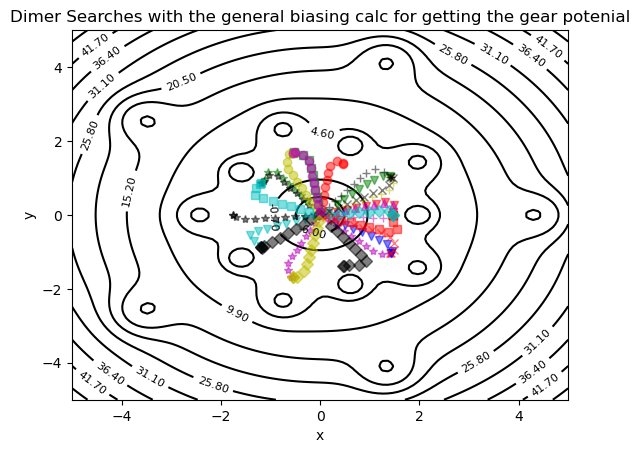

In [16]:
import copy
from ase.calculators.mixing import LinearCombinationCalculator
ts_list=[]
only_ts_list = []
### Set up the system
atoms = fcc100('Pd', size=(1, 1, 1), vacuum=10.0)

pos = atoms.get_positions()
pos[0][0]+=1e-10
atoms.set_positions(pos)
c = FixedPlane(indices=[atom.index for atom in atoms], direction=[0, 0, 1])

atoms.set_constraint(c)
for i in range(25):
    initial = copy.deepcopy(atoms)
    jax_calc = General_Bias_Calculator(_cvs,f_cvs)
    initial.calc = jax_calc
    
    print(i)
    '''print('Force', initial.get_forces())
    pos = initial.get_positions()
    print(pos)
    pos[0][0]+=-1
    pos[0][1]+=0
    print(pos)
    initial.set_positions(pos)
    print('Force', initial.get_forces())'''
    BFGS(initial).run(fmax =0.01,steps=50)

    d_control = DimerControl(initial_eigenmode_method='gauss',
                        displacement_method='gauss',
                        gauss_std= 0.17,  #vdw-radius of pd = 1.63 ang
                        displacement_center= 0,
                        displacement_radius= 10, #vdw-radius of pd = 1.63 ang
                        #number_of_displacement_atoms = 126,
                        logfile=f'test_{i}.log')
    d_atoms = MinModeAtoms(initial, d_control)        
    d_atoms.displace()

    ### Converge to a saddle point:
    dim_rlx = MinModeTranslate(d_atoms,
                            trajectory=f'test_{i}.traj',
                            logfile=f'test_{i}.log')
    dim_rlx.run(fmax=0.001,steps=50)
    positions = extract_positions(f'test_{i}.traj')
    ts_list.append(positions)
    
# Define the 2D function to plot
def f_j(x,y):
    r = jnp.sqrt(x**2 + y**2)
    large_min = jnp.exp(-0.5*((r)/0.5)**2)
    small_mins = 0
    for i in range(5):
        x0 = 2*jnp.cos(2*jnp.pi*i/5)
        y0 = 2*jnp.sin(2*jnp.pi*i/5)
        small_mins += 1*jnp.exp(-0.5*((x-x0)**2 + (y-y0)**2)/0.2**2)

        x1 = 2.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/5)
        y1 = 2.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/5)
        small_mins += 0.8*jnp.exp(-0.2*((x-x1)**2 + (y-y1)**2)/0.2**2)

        x2=4.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/(2.5))
        y2= 4.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/(2.5))
        small_mins += 1*jnp.exp(-0.1*((x-x2)**2 + (y-y2)**2)/0.2**2)

    return -10*large_min - 10*small_mins + (x**2 +y**2)

# Create a meshgrid for x and y values
x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x, y)

# Compute the function values for each (x,y) pair
Z = f_j(X, Y)

# Manually set the contour levels to focus on the range of function values around the central minimum
levels = np.linspace(-6, 100, 21)

# Define a list of possible marker styles
marker_styles = ['o', 's', 'D', '^', 'v', '*', 'x', '+']
color_styles = ['r','g','b','k','c','m','y']

# Generate an array of randomly selected marker styles
markers = np.random.choice(marker_styles, size=len(ts_list))
colors = np.random.choice(color_styles, size=len(ts_list))

color_markers = []
for i in range(len(ts_list)):
    marker_color = markers[i] + colors[i]
    color_markers.append(marker_color)
print(color_markers)

# Create the contour plot with line styles
fig, ax = plt.subplots()
contours = ax.contour(X, Y, Z, levels=levels, colors='k', linestyles='solid')
ax.clabel(contours, inline=True, fontsize=8, fmt='%.2f')


for n, positions in enumerate(ts_list):
    for point in positions[::2]: #Every second element in the list is engouh to project the pathway
        ax.plot(point[0][0], point[0][1], color_markers[n], markersize=6, alpha=0.5)

plt.xlabel('x')
plt.ylabel('y')
# Set the axes limits and title
ax.set_xlim(-5, 5)
ax.set_ylim(-5, 5)
ax.set_title('Dimer Searches with the general biasing calc for getting the gear potenial')

plt.show() 

# Molecular Dynamincs

For further testing and trying out biASE some MD simulations have been performed
First a 1D example


In [17]:
def _cvs(atom_pos):
    '''Collective variable from the x and y cooridinate'''
    x = atom_pos[0][0]
    y = atom_pos[0][1]
    return jnp.array([x,y])

def f_dw_cvs(cvs,scale=0.1):
    '''Double-Well'''
    x =  cvs[0]
    y =  cvs[1]
    return scale*((x**2 - 1)**2 + y**2)

def f_cvs(cvs,scale=0.1):
    x = cvs[0]
    y = cvs[1]
    r = jnp.sqrt(x**2 + y**2)
    large_min = jnp.exp(-0.5*((r)/0.5)**2)
    small_mins = 0
    for i in range(5):
        x0 = 1*jnp.cos(2*jnp.pi*i/5)
        y0 = 1*jnp.sin(2*jnp.pi*i/5)
        small_mins += 1*jnp.exp(-0.5*((x-x0)**2 + (y-y0)**2)/0.2**2)

        x1 = 1.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/5)
        y1 = 1.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/5)
        small_mins += 0.8*jnp.exp(-0.2*((x-x1)**2 + (y-y1)**2)/0.2**2)

        x2=4.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/(2.5))
        y2= 4.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/(2.5))
        small_mins += 1*jnp.exp(-0.1*((x-x2)**2 + (y-y2)**2)/0.2**2)

    return scale*(-10*large_min - 10*small_mins + (x**2 +y**2))

def f_cvs_1D(cvs):
    x = cvs[0]
    return x**2*(1.-x)**2

def deriv_f_cvs_1D(cvs):
    x = cvs[0]
    df_dx = 2*x*(1.-x)*(2*x-1.)
    return np.array([[df_dx,0,0]])

def deriv_f_cvs_1D(cvs, h=1e-4):
    f0 = f_cvs_1D(cvs)
    x = cvs[0]
    fx = f_cvs_1D([x+h])
    fd = (fx - f0) / h
    return np.array([[fd,0,0]])

In [18]:
def plot_2d_bias(f_bias,rangeCV1=[-1,1],rangeCV2=[-1,1],N_points=100,trajectory=None):
    x = np.linspace(rangeCV1[0], rangeCV1[1], N_points)
    y = np.linspace(rangeCV2[0], rangeCV2[1], N_points)

    X, Y = np.meshgrid(x, y)
    CVs=[X,Y]
    Z = f_bias(CVs)
    
    plt.contour(X, Y, Z, 50, cmap='RdGy')
    plt.colorbar()
    
    if trajectory==None:
        plt.show()
    else:
        plt.plot(trajectory[0],trajectory[1])
        plt.xlabel('x')
        plt.ylabel('y')
        plt.savefig('2D_plot.png')
        plt.show()

def plot_1d_bias(f_bias,rangeCV1=[-0.1,1.5],N_points=100,trajectory=None):
    x = np.linspace(rangeCV1[0], rangeCV1[1], N_points)
    
    try:
        CVs=[x] #needs to be an array for the spring method
        Z = f_bias(CVs)
        plt.plot(x, Z)
    except:
        CVs=np.array(x) #needs to be an array for the spring method
        Z = f_bias(CVs)
        plt.plot(x, Z)
    if trajectory==None:
        plt.show()
    else:
        plt.hist(trajectory[0],density=True,bins=100,range=rangeCV1)
        plt.xlabel('x')
        plt.ylabel('E')
        plt.savefig('1D_DW_C.png')
        plt.show()
        

        

# 1D MD example

In [22]:
from ase.atoms import Atoms
from ase import units
from ase.io import read


from ase.md.langevin import Langevin
from ase.md.verlet import VelocityVerlet
from ase.md.velocitydistribution import MaxwellBoltzmannDistribution
from ase.constraints import FixedPlane

In [23]:
atoms = Atoms('C',[[1.0,0.0,0.0]])
jax_calc = General_Bias_Calculator(_cvs,f_cvs_1D)
atoms.calc = jax_calc 

In [24]:
from ase.md.andersen import Andersen
'''c1 = FixedPlane(
    [0],
    [0, 0, 1],
)

atoms.set_constraint(c1)

c2 = FixedPlane(
    [0],
    [0, 1, 0],
)
atoms.set_constraint(c1)
atoms.set_constraint(c2)'''

MaxwellBoltzmannDistribution(atoms, temperature_K=1000)
print(atoms.get_velocities())

dyn = Langevin(atoms, timestep=.5 * units.fs, temperature_K=500, friction=0.01, trajectory='md.traj',fixcm=False)#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#

#dyn = VelocityVerlet(atoms, timestep=1.0 * units.fs, trajectory='md.traj')

N_steps = int(1e5)
dyn.run(N_steps) 

[[0.10480832 0.08707358 0.22043812]]


True

In [25]:
traj = read('md.traj@::1')
print(len(traj))

#print(traj)
#print()
x = []
y = np.zeros(N_steps+1)
z = np.zeros(N_steps+1)

# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x.append(xyz[0][0])
    y[i] = xyz[0][1]
    z[i] = xyz[0][2]
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()

100001


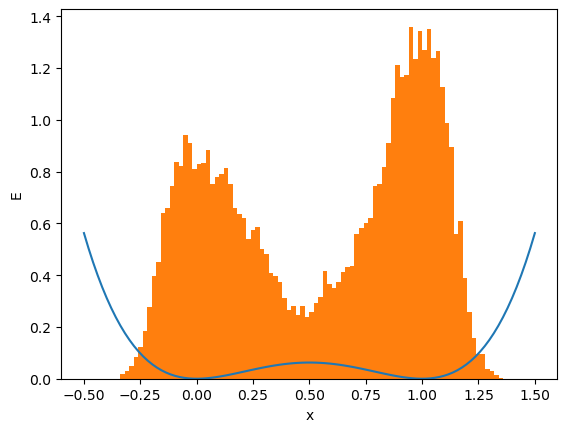

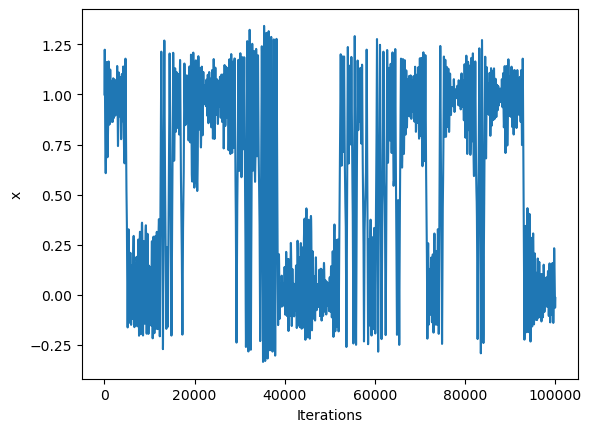

In [26]:
plot_1d_bias(f_cvs_1D,trajectory=[x],rangeCV1=[-0.5,1.5])

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(x)
#plt.plot(y)
#plt.plot(z)
plt.savefig('X_movement_DW_C.png')

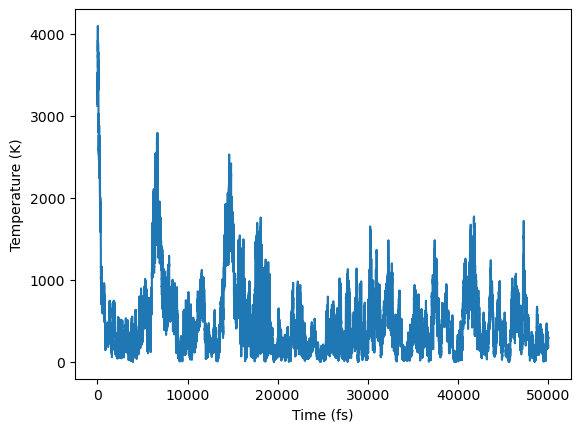

481.795159006199


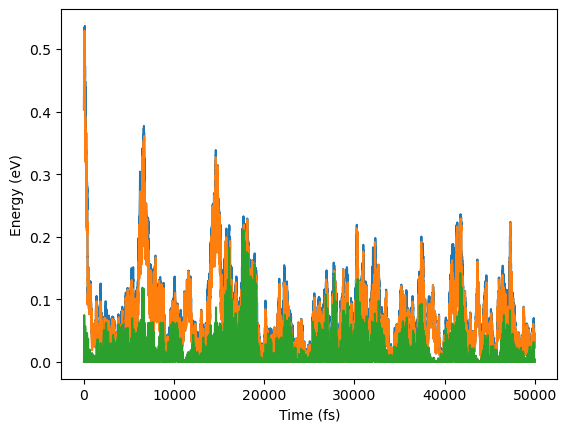

0.5368144645579845 0.001431354335807548 0.08423458927199136


In [27]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))


# Plot the temperature as a function of time

time = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time, energy)# / units.kB)
plt.plot(time, kin)
plt.plot(time, pot)
plt.xlabel('Time (fs)')
plt.ylabel('Energy (eV)')
plt.show()
print(max(energy),min(energy),np.average(energy))

# Also an NVE MD is intresting

100001


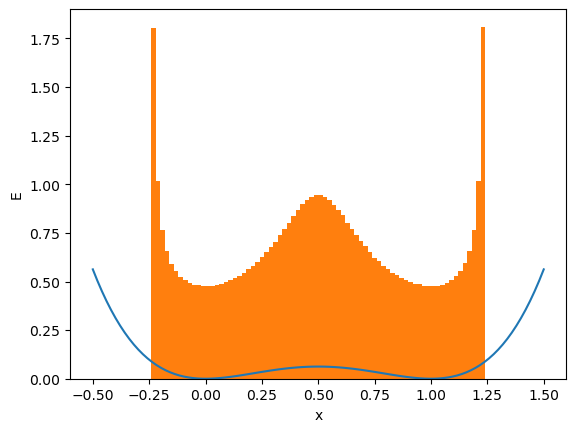

In [29]:
from ase import Atoms
from ase.md.velocitydistribution import MaxwellBoltzmannDistribution
from ase import units
from ase.md import VelocityVerlet
import numpy as np

# Set up the system
atoms = Atoms('H',[[0.6,0.0,0.0]])
jax_calc = General_Bias_Calculator(_cvs,f_cvs_1D)
atoms.calc = jax_calc 

# Set the initial velocities using a Maxwell-Boltzmann distribution
MaxwellBoltzmannDistribution(atoms, temperature_K=1000)

# Define the integration timestep
timestep = .5*units.fs

# Define the number of steps to run the simulation
N_steps = int(1e5)

# Set up the integrator
dyn = VelocityVerlet(atoms, timestep,trajectory='md.traj')
dyn.run(N_steps)


# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)
traj = read('md.traj@::1')
print(len(traj))

#print(traj)
#print()
x = []
#y = np.zeros(N_steps+1)
#z = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x.append(xyz[0][0])
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    #pot[i] = snap.get_potential_energy()
    #kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
plot_1d_bias(f_cvs_1D,trajectory=[x],rangeCV1=[-0.5,1.5])


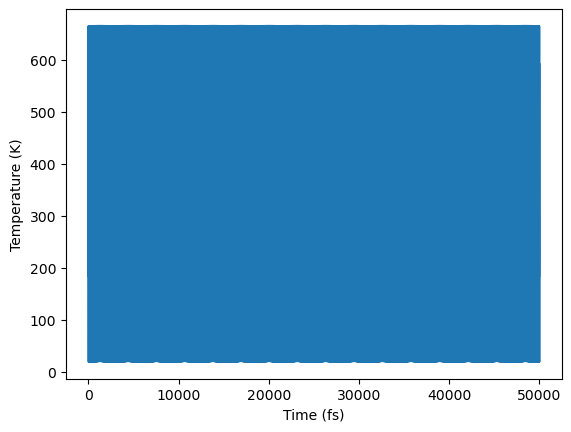

In [30]:
# Plot the temperature as a function of time

time = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time, temperatures)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVE_DW_temp.png')
plt.show()


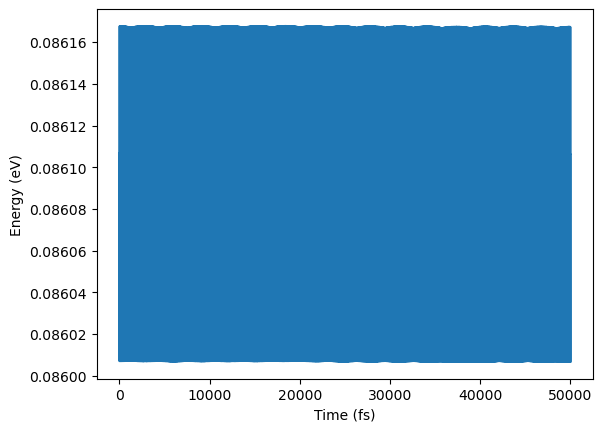

0.08616775425779548 0.08600665111191758


In [31]:
# Plot the temperature as a function of time

time = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time, energy)
#plt.plot(time, kin)
#plt.plot(time, pot)
plt.xlabel('Time (fs)')
plt.ylabel('Energy (eV)')
plt.savefig('NVE_DW_energy.png')
plt.show()
print(max(energy),min(energy))

# A Comparison with an analytical Calculator

In [32]:
import jax.numpy as jnp
from jax import jit
from jax import grad ,jacfwd,jacrev


class Analytical_Calculator(Calculator):
    """ 
    """
    implemented_properties=['energy','forces']#,'hessian']
    def __init__(self, cv_function, function, deriv, use_jit = True, **kwargs):
        """ Sets up the Calculator from ase for example self.results or allows get_forces (and similar things) to work"""
        Calculator.__init__(self, **kwargs)
        
        self.cv_function = cv_function
        self.function = function
        self.deriv = deriv
            
            
    def calculate(self, atoms=None, properties=['energy','forces'], system_changes=all_changes):
        """ Calculates all the implemented properties. This method needs to call the .calculate form the Calculator class"""

        Calculator.calculate(self, atoms, properties, system_changes) # for setting up all necessary stuff DO NOT define ANY stuff by hand this method defines! otherwise it won't recoginze changes
        #print('prop', properties)
       
        self.energy = 0
        
        atoms_pos = atoms.get_positions()
        self.cvs = self.cv_function(atoms_pos)
        #print('CVs ', self.cvs)
        self.energy += self.function(self.cvs)
        #print('Energy' ,self.energy)
    
        if 'forces' in properties: 
            self.forces = -self.deriv(self.cvs)
            #print(self.forces)
            self.results['forces'] = np.asarray(self.forces)
        self.results['energy'] = self.energy

[[-0.00010005 -0.         -0.        ]]
[[0.19652769 0.         0.29791686]]
10001


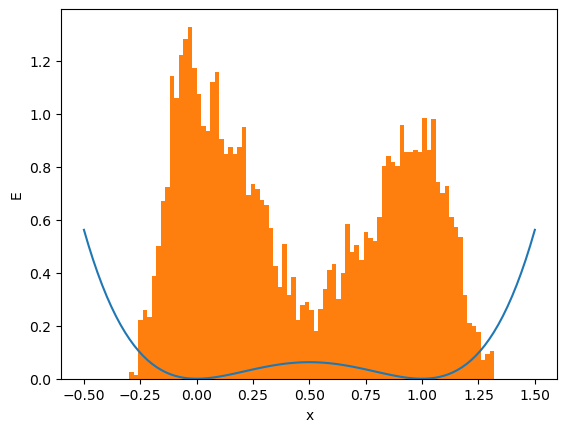

In [33]:
atoms = Atoms('H',[[1.0,0.0,0.0]])
ana_calc = Analytical_Calculator(_cvs,f_cvs_1D,deriv_f_cvs_1D)
atoms.calc = ana_calc 
c1 = FixedPlane(
    [0],
    [0, 0, 1],
)

atoms.set_constraint(c1)

c2 = FixedPlane(
    [0],
    [0, 1, 0],
)

atoms.set_constraint(c2)
print(atoms.get_forces())
MaxwellBoltzmannDistribution(atoms, temperature_K=1000)
print(atoms.get_velocities())

dyn = Langevin(atoms, timestep=.50 * units.fs, temperature_K=500, friction=1,
                     trajectory='md.traj', fixcm=False)

#dyn = VelocityVerlet(atoms, timestep=1.0 * units.fs, trajectory='md.traj')

N_steps = int(1e5)
dyn.run(N_steps) 

# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)
traj = read('md.traj@::1')
print(len(traj))

#print(traj)
#print()
x = []
#y = np.zeros(N_steps+1)
#z = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x.append(xyz[0][0])
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    #pot[i] = snap.get_potential_energy()
    #kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()    
    
plot_1d_bias(f_cvs_1D,trajectory=[x],rangeCV1=[-0.5,1.5])

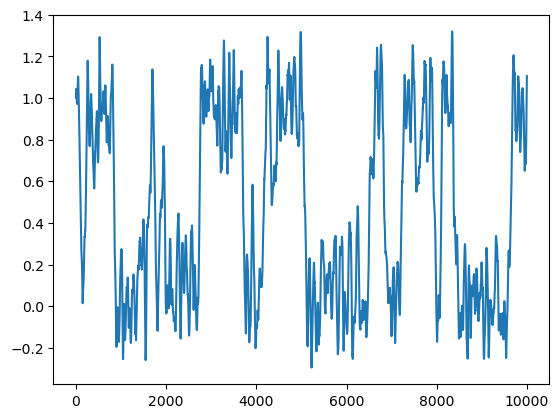

In [34]:
plt.plot(x)

In [ ]:
# Set up the system
atoms = Atoms('H',[[0.6,0.0,0.0]])
ana_calc = Analytical_Calculator(_cvs,f_cvs_1D,deriv_f_cvs_1D)
atoms.calc = ana_calc

# Set the initial velocities using a Maxwell-Boltzmann distribution
MaxwellBoltzmannDistribution(atoms, temperature_K=1000)

# Define the integration timestep
timestep = .5*units.fs

# Define the number of steps to run the simulation
N_steps = int(1e5)

# Set up the integrator
dyn = VelocityVerlet(atoms, timestep,trajectory='md.traj')
dyn.run(N_steps)


# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)
traj = read('md.traj@::1')
print(len(traj))

#print(traj)
#print()
x = []
#y = np.zeros(N_steps+1)
#z = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x.append(xyz[0][0])
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    #pot[i] = snap.get_potential_energy()
    #kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
plot_1d_bias(f_cvs_1D,trajectory=[x],rangeCV1=[-0.5,1.5])


10001


In [ ]:
# Plot the temperature as a function of time

time = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time, temperatures)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.show()


# Plot the temperature as a function of time

time = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time, energy)# / units.kB)
#plt.plot(time, kin)
#plt.plot(time, pot)
plt.xlabel('Time (fs)')
plt.ylabel('Energy (eV)')
plt.show()
print(max(energy),min(energy))

# 2D MD example


In [19]:

atoms = Atoms('H',[[-1.0,0.0,0.0]])

jax_calc = General_Bias_Calculator(_cvs,f_cvs)
atoms.calc = jax_calc 


c = FixedPlane(
    [0],
    [0, 0, 1],
)

atoms.set_constraint(c)


MaxwellBoltzmannDistribution(atoms, temperature_K=2000)
print(atoms.get_velocities())

dyn = Langevin(atoms, timestep=0.5 * units.fs, temperature_K=1000, friction=1,trajectory='md.traj',fixcm=False)

#dyn = VelocityVerlet(atoms, timestep=1.0 * units.fs, trajectory='md.traj')

N_steps = int(1e5)
dyn.run(N_steps) 

[[-0.00404939 -0.18984643  0.        ]]


True

100001


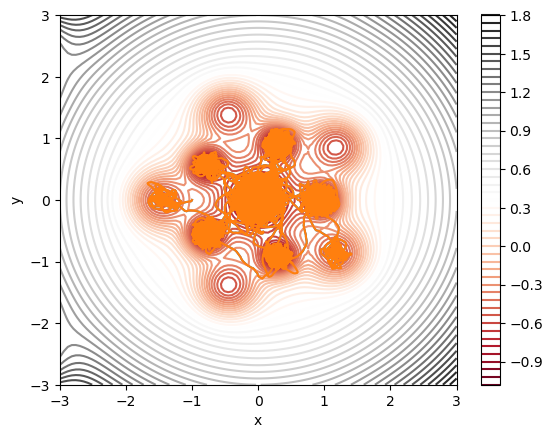

In [20]:
traj = read('md.traj@:')
print(len(traj))
#print(traj)
#print()
x = np.zeros(N_steps+1)
y = np.zeros(N_steps+1)
z = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x[i] = xyz[0][0]
    y[i] = xyz[0][1]
    z[i] = xyz[0][2]

plt.plot(x,y)

plot_2d_bias(f_cvs,trajectory=[x,y],rangeCV1=[-3,3],rangeCV2=[-3,3])

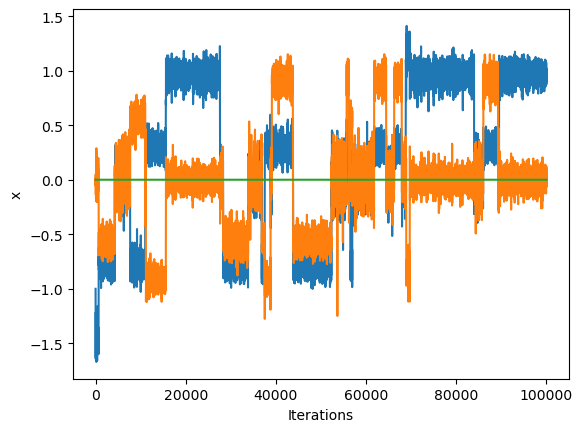

In [21]:
plt.plot(x)
plt.plot(y)
plt.plot(z)
plt.xlabel('Iterations')
plt.ylabel('x')
plt.savefig('Coordinates_2D_plot.png')

# Also a two atom example like two atoms with a spring are interessting

In [ ]:
def spring_2_atoms(d,d0=1,k=1):
    return 0.5*k*(d-d0)**2

def _distance(atom_pos):
    return jnp.sqrt(sum((atom_pos[0]-atom_pos[1])**2))

harmonic_molecule_calc = General_Bias_Calculator(_distance,spring_2_atoms)

In [ ]:
atoms = Atoms('H2',[[1.0,0.0,0.0],[2.0,0.0,0.0]])
atoms.calc = harmonic_molecule_calc
print(atoms.get_forces())

MaxwellBoltzmannDistribution(atoms, temperature_K=1000)
print(atoms.get_velocities())

dyn = Langevin(atoms, timestep=.50 * units.fs, temperature_K=500, friction=0.01,
                     trajectory='md.traj',fixcm=False)


N_steps = int(1e5)
dyn.run(N_steps) 


# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)
traj = read('md.traj@::1')
print(len(traj))

#print(traj)
#print()
x = []
#y = np.zeros(N_steps+1)
#z = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x.append(_distance(xyz))
    #y[i] = xyz[0][1]
    #z[i] = xyz[0][2]
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
    
x = np.array(x)
print(x.shape)
plot_1d_bias(spring_2_atoms,trajectory=[x],rangeCV1=[-1.5,3.5])


In [ ]:
# Plot the temperature as a function of time

time = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_temp.png')
plt.show()
print(np.average(np.array(temperatures)))
print(max(temperatures),min(temperatures))

# Plot the temperature as a function of time

time = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time[::1000], energy[::1000])# / units.kB)
plt.plot(time[::1000], kin[::1000])
plt.plot(time[::1000], pot[::1000])
plt.xlabel('Time (fs)')
plt.ylabel('Energy (eV)')
plt.savefig('NVT_energy_full.png')
plt.show()
print(max(energy),min(energy))

In [ ]:
# Set up the system
atoms = Atoms('H2',[[1.0,0.0,0.0],[2.0,0.0,0.0]])
atoms.calc = harmonic_molecule_calc

# Set the initial velocities using a Maxwell-Boltzmann distribution
MaxwellBoltzmannDistribution(atoms, temperature_K=1000)
print(atoms.get_temperature())
# Define the integration timestep
timestep = .5*units.fs

# Define the number of steps to run the simulation
N_steps = int(1e4)

# Set up the integrator
dyn = VelocityVerlet(atoms, timestep,trajectory='md.traj')
dyn.run(N_steps)


# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)
traj = read('md.traj@::1')
print(len(traj))

#print(traj)
#print()
x = []
#y = np.zeros(N_steps+1)
#z = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x.append(_distance(xyz))
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()
plot_1d_bias(spring_2_atoms,trajectory=[x],rangeCV1=[-1.5,3.5])



In [ ]:
# Plot the temperature as a function of time

time = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time[::100], temperatures[::100])#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVE_temp.png')
plt.show()
print(np.average(np.array(temperatures)))
print(max(temperatures),min(temperatures))

# Plot the temperature as a function of time
fig, ax = plt.subplots()
time = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time[::100], energy[::100])# / units.kB)
plt.plot(time[::100], kin[::100])
plt.plot(time[::100], pot[::100])
plt.xlabel('Time (fs)')
plt.ylabel('Energy (eV)')
fig.subplots_adjust(left=0.2)
plt.savefig('NVE_energy_full.png')
plt.show()
print(max(energy),min(energy))